# Visualization with grstbx

This notebook opens a time series of hGRS L2A products and displays them with the tools of
[grstbx](https://github.com/Tristanovsk/grstbx), the toolbox of the GRS processor: true-colour
composites, cropping to an area of interest, multi-date spectra and time series, and the interactive
spectral and parameter viewers.

The example uses the 14 EnMAP L2A products of Lake Trasimeno (Italy) processed with hGRS from October 2022
to September 2025 (see [Batch processing](batch_processing.ipynb)). The last section needs a running
Jupyter kernel and is not executed in this documentation.

Install grstbx in the hGRS environment with `pip install grstbx` (or from its repository).

In [1]:
import glob

import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
import pyproj
import rioxarray  # noqa: F401, enables the .rio accessor

from grstbx import subset, utils, visual

## Open the L2A products

The products are opened lazily: only the pixels needed by each figure are read.

In [2]:
l2a_dir = 'L2A/Trasimeno'
files = sorted(glob.glob(f'{l2a_dir}/ENMAP01-____L2A_hgrs-*.nc'))

products = [xr.open_dataset(file, decode_coords='all', chunks={}) for file in files]
products = sorted(products, key=lambda product: product.time.values)

pd.DataFrame({'date': [str(product.time.dt.date.values) for product in products],
              'hGRS version': [product.attrs['hgrs_version'] for product in products],
              'size (y, x)': [(product.sizes['y'], product.sizes['x']) for product in products]})

,date,hGRS version,"size (y, x)"
0,2022-10-05,1.1.1,"(1227, 1253)"
1,2024-07-06,1.1.1,"(1221, 1295)"
2,2024-08-17,1.1.1,"(1247, 1598)"
3,2024-11-06,1.1.1,"(1251, 1597)"
4,2025-02-03,1.1.1,"(1229, 1375)"
5,2025-02-07,1.1.1,"(1221, 1304)"
6,2025-03-10,1.1.1,"(1223, 1263)"
7,2025-04-06,1.1.2,"(1221, 1261)"
8,2025-04-06,1.1.2,"(1222, 1260)"
9,2025-05-03,1.1.2,"(1222, 1263)"


The 2025-04-06 acquisition covers the lake with two tiles, which are kept as two images.

## From the hGRS layout to the grstbx layout

An hGRS L2A product holds, in a single NetCDF file:

* the full-resolution variables on the `x`, `y` grid of the L1C image: `Rrs` (with a `wl` dimension)
  and the sunglint amplitude `brdfg_full`;
* the variables retrieved on the coarse grid of the mega-pixels, on `xc`, `yc`: aerosol optical
  thickness `aot_ref` (and its smoothed version `aot_ref_smoothed`), water vapor `tcwv`, sunglint
  `brdfg` and their uncertainties.

grstbx stores the coarse-grid data in a separate *ancillary* dataset, on `xc`, `yc` as well. Splitting the
hGRS product in the same way is enough to use the grstbx tools that take an `ancillary` argument.

In [3]:
def split_hgrs(product):
    '''Split an hGRS L2A product into its full-resolution (x, y) and coarse-grid (xc, yc) variables.'''
    full = product[[name for name in product.data_vars if {'x', 'y'} <= set(product[name].dims)]]
    ancillary = product[[name for name in product.data_vars if {'xc', 'yc'} <= set(product[name].dims)]]
    return full, ancillary


product, ancillary = split_hgrs(products[2])   # 2024-08-17
product

<xarray.Dataset> Size: 1GB
Dimensions:      (wl: 92, y: 1247, x: 1598)
Coordinates:
  * wl           (wl) float64 736B 418.4 424.0 429.5 ... 1.093e+03 1.105e+03
  * y            (y) float64 10kB 4.8e+06 4.8e+06 ... 4.763e+06 4.763e+06
  * x            (x) float64 13kB 2.431e+05 2.431e+05 ... 2.909e+05 2.91e+05
    spatial_ref  int64 8B ...
    time         datetime64[ns] 8B ...
Data variables:
    Rrs          (wl, y, x) float64 1GB dask.array<chunksize=(31, 416, 533), meta=np.ndarray>
    brdfg_full   (y, x) float64 16MB dask.array<chunksize=(1247, 1598), meta=np.ndarray>
Attributes: (12/42)
    description:                     PRISMA L2A-hGRS cube data
    L1C_product_name:                ENMAP01-____L1C-DT0000088121_20240817T10...
    acquisition_date:                2024-08-17 10:22:30.993191
    vnir_index:                      [  0   1   2   3   4   5   6   7   8   9...
    swir_index:                      [ 79  81  84  86  88  90  93  95  97  99...
    vnir_index_tokeep:               [ 0  1  2  3  4  5  6  7  8  9 10 11 12 ...
    ...                              ...
    to3c:                            0.0062910388223826885
    tno2c:                           3.0029445952095557e-06
    tch4c:                           0.009911714121699333
    psl:                             1013
    coef_abs_scat:                   0.35
    altitude:                        0

## True-colour composite and area of interest

The area of interest (AOI) is a box of 1.5 km x 1.5 km at the centre of the lake. The image is first cropped
to the lake with `subset.crop_l2a`, keeping the pixels outside the box (`mask_outside=False`), then
displayed with `utils.plot_rgb` in its UTM projection.

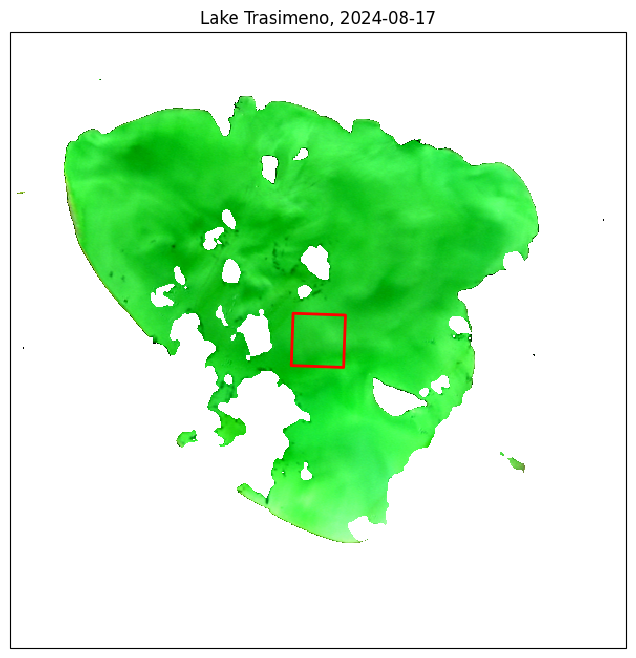

In [4]:
to_lonlat = pyproj.Transformer.from_crs(product.rio.crs, 4326, always_xy=True)
lon, lat = to_lonlat.transform(265000, 4779500)   # centre of the lake (UTM 33N)

lake = subset.aoi_from_box(lon, lat, width=17000, height=17000)
aoi = subset.aoi_from_box(lon, lat, width=1500, height=1500)

lake_product, _ = subset.crop_l2a(product, lake, mask_outside=False)
ax = utils.plot_rgb(lake_product, aoi=aoi, figsize=(8, 8))
ax.set_title(f'Lake Trasimeno, {product.time.dt.date.values}');

## Crop to the area of interest

`subset.crop_l2a` cuts the product to the AOI and flags the pixels outside the polygon as missing; the
ancillary data are cropped to the same box enlarged by one mega-pixel, so that they can still be
interpolated over the whole AOI. The bands removed by hGRS (strong gaseous absorption) are NaN: they are
left out of the statistics and appear as gaps in the plot.

number of water pixels: 2502
aerosol optical thickness at 550 nm in the AOI: 0.244


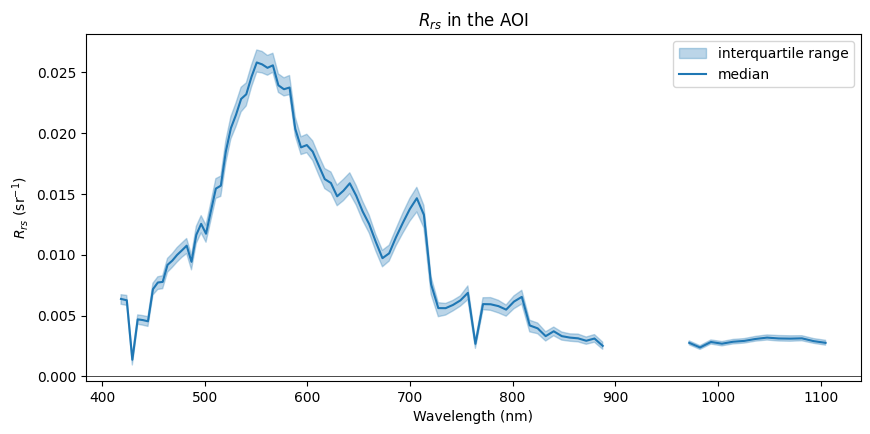

In [5]:
aoi_product, aoi_ancillary = subset.crop_l2a(product, aoi, ancillary=ancillary)
aoi_product = aoi_product.load()

rrs = aoi_product.Rrs.stack(pixel=['y', 'x']).dropna('pixel', how='all').dropna('wl', how='all')
print('number of water pixels:', rrs.sizes['pixel'])
print('aerosol optical thickness at 550 nm in the AOI: '
      f'{float(aoi_ancillary.aot_ref_smoothed.mean()):.3f}')

# statistics per band, with the removed bands back as NaN (gaps in the plot)
stats = xr.Dataset({'median': rrs.median('pixel'),
                    'q25': rrs.quantile(0.25, 'pixel').drop_vars('quantile'),
                    'q75': rrs.quantile(0.75, 'pixel').drop_vars('quantile')}).reindex(wl=aoi_product.wl)

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.fill_between(stats.wl, stats.q25, stats.q75, color='tab:blue', alpha=0.3, label='interquartile range')
stats['median'].plot(ax=ax, color='tab:blue', label='median')
ax.axhline(0, color='k', lw=0.5)
ax.set(xlabel='Wavelength (nm)', ylabel='$R_{rs}$ (sr$^{-1}$)', title='$R_{rs}$ in the AOI')
ax.legend();

## Coarse-grid parameters

Aerosol optical thickness, water vapor and sunglint retrieved on the mega-pixels, over the lake. The
grey cells are the mega-pixels without enough water pixels for the retrieval.

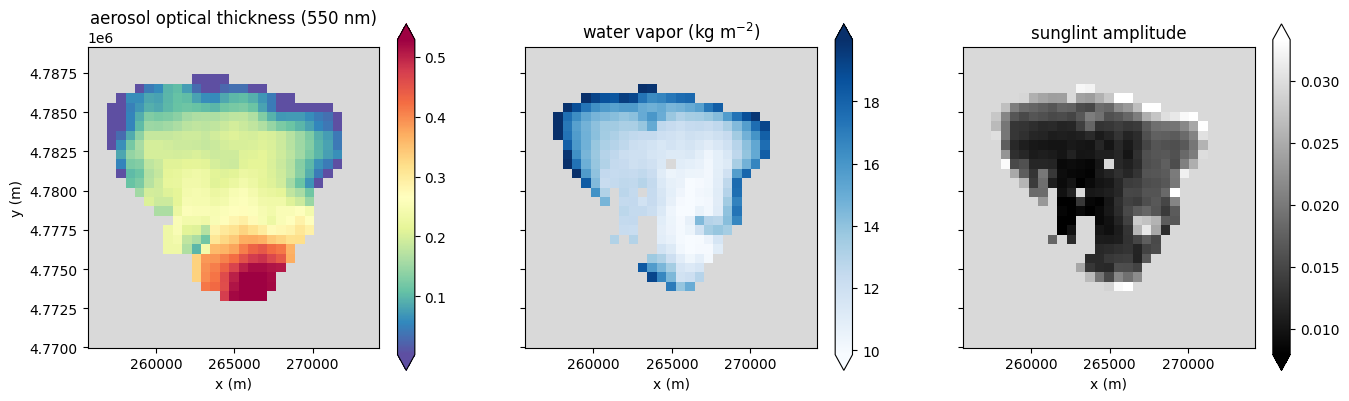

In [6]:
_, lake_ancillary = subset.crop_l2a(product, lake, ancillary=ancillary, mask_outside=False)

params = {'aot_ref_smoothed': ('aerosol optical thickness (550 nm)', 'Spectral_r'),
          'tcwv': ('water vapor (kg m$^{-2}$)', 'Blues'),
          'brdfg': ('sunglint amplitude', 'gray')}

fig, axs = plt.subplots(1, 3, figsize=(16, 4.5), sharex=True, sharey=True)
for ax, (name, (label, cmap)) in zip(axs, params.items()):
    ax.set_facecolor('0.85')
    lake_ancillary[name].plot.imshow(ax=ax, cmap=cmap, robust=True, cbar_kwargs={'label': ''})
    ax.set(title=label, aspect='equal', xlabel='x (m)', ylabel='')
axs[0].set_ylabel('y (m)');

## Multi-date spectra and time series

`visual.Multiscale` gives a lazy access to a series of images, each on its own grid: the images do not
need to be regridded on a common grid. It is used by the interactive viewers, and also directly, here to
extract the spectra of a point at all the dates.

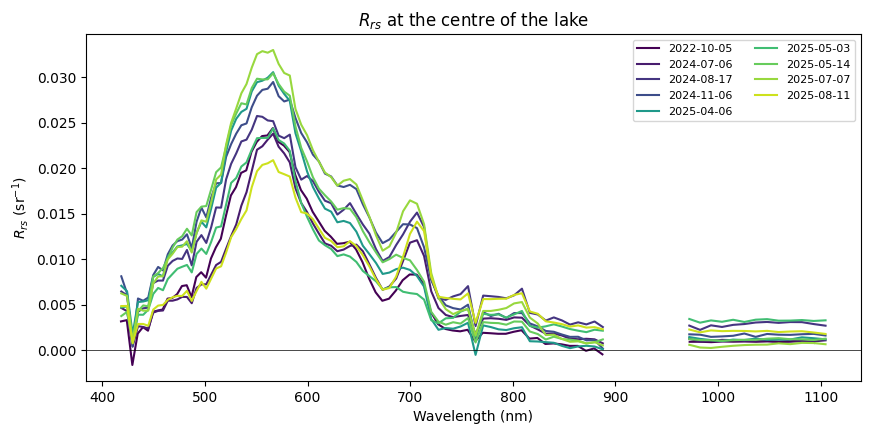

In [7]:
times = [product.time.values for product in products]
spectral_series = visual.Multiscale([[product.Rrs] for product in products], times)

x0, y0 = 265000, 4779500   # centre of the lake (UTM 33N)
fig, ax = plt.subplots(figsize=(10, 4.5))
colors = plt.cm.viridis(np.linspace(0, 1, len(times)))
for itime, color in enumerate(colors):
    spectrum = spectral_series.pixel(itime, x0, y0)
    if spectrum is not None and np.isfinite(spectrum).any():
        ax.plot(spectrum.wl, spectrum, color=color, label=str(pd.Timestamp(times[itime]).date()))
ax.axhline(0, color='k', lw=0.5)
ax.set(xlabel='Wavelength (nm)', ylabel='$R_{rs}$ (sr$^{-1}$)', title='$R_{rs}$ at the centre of the lake')
ax.legend(ncol=2, fontsize=8);

The dates without a spectrum are those where the centre of the lake is masked (clouds, or outside
the image).

For the time series and the parameter viewer, each image is reduced to a Dataset of 2D maps: here the
reflectance at 560 nm (green) and 705 nm (red-edge, sensitive to chlorophyll-a) and the sunglint
amplitude.

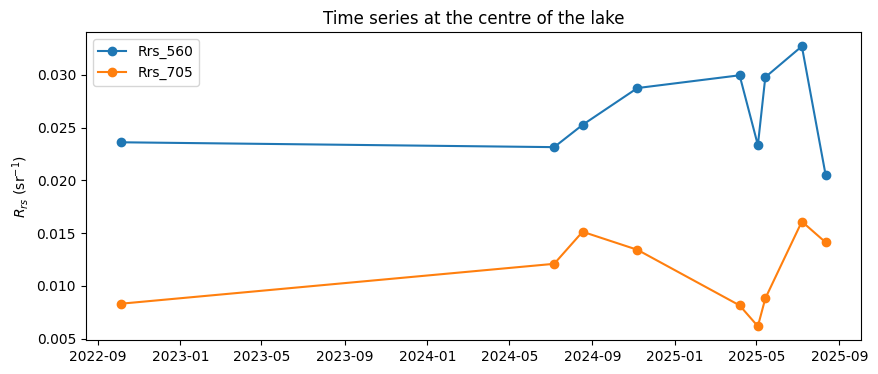

In [8]:
def parameter_maps(product):
    '''2D maps of one hGRS L2A product, for the time series and the parameter viewer.'''
    maps = xr.Dataset({'Rrs_560': product.Rrs.sel(wl=560, method='nearest', drop=True),
                       'Rrs_705': product.Rrs.sel(wl=705, method='nearest', drop=True),
                       'sunglint': product.brdfg_full})
    return maps.rio.write_crs(product.rio.crs)


parameter_series = visual.Multiscale([[parameter_maps(product)] for product in products], times)

fig, ax = plt.subplots(figsize=(10, 4))
for name in ['Rrs_560', 'Rrs_705']:
    series = parameter_series.timeseries(name, x0, y0).dropna()
    ax.plot(series.index, series.values, 'o-', label=name)
ax.set(ylabel='$R_{rs}$ (sr$^{-1}$)', title='Time series at the centre of the lake')
ax.legend();

## Interactive viewers

The following cells need a running Jupyter kernel (they are not executed in this documentation). Only the
pixels visible on the screen are read, at the resolution of the screen.

### Spectral viewer

Browse the dates and the bands (or the true-colour composite), draw points on the map to plot their
full-resolution spectra; the spectrum of the pixel under the mouse is plotted live.

In [ ]:
import panel as pn

pn.extension()
viewer = visual.ViewSpectral(spectral_series, reproject=True, minmaxvalues=(0, 0.03), minmax=(0, 0.06),
                             cmap='cmo.turbid', poi=[(lon, lat)])
viewer.visu()

The points drawn on the map, in longitude and latitude, for further analysis:

In [ ]:
points = viewer.get_points()
points

### Parameter viewer

Browse the maps of `parameter_maps` by date, and click on the map to plot the time series of the
selected parameter.

In [ ]:
param_viewer = visual.ViewParam(parameter_series, reproject=True, minmaxvalues=(0, 0.03),
                                minmax=(0, 0.06), cmap='cmo.algae', poi=[(lon, lat)])
param_viewer.visu()

## What does not apply to hGRS products

* `grstbx.driver.L2grs` and `subset.open_l2a` read GRS products (product folder with ancillary file, or
  Zarr store): open hGRS products with `xarray.open_dataset` as above.
* `grstbx.masking.Masking` decodes the `flags` bitmask of GRS products; hGRS products have no `flags`
  variable, the masked pixels (land, clouds, cloud shadows) are NaN in `Rrs`.